In [5]:
# Cell 1 - Environment setup and raw data ingestion
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42

# Fleksibel mendeteksi nama file CSV
candidates = [
    Path("cervical_cancer_master_cleaned.csv"),
]

DATA_PATH = None
for p in candidates:
    if p.exists():
        DATA_PATH = p
        break

if DATA_PATH is None:
    # Fallback pencarian file csv apa saja di folder aktif
    csv_files = list(Path.cwd().glob("*.csv"))
    if csv_files:
        DATA_PATH = csv_files[0]
    else:
        raise FileNotFoundError("File CSV dataset tidak ditemukan di folder kerja!")

df_raw = pd.read_csv(DATA_PATH, na_values="?")

# Tentukan nama kolom target
target_col = "target" if "target" in df_raw.columns else "Biopsy"

target_counts = df_raw[target_col].value_counts().to_dict()
missing_summary = df_raw.isnull().sum()
cols_with_na = missing_summary[missing_summary > 0]

print(f"Membaca file: {DATA_PATH.name}")
print(f"rows={df_raw.shape[0]} | cols={df_raw.shape[1]}")
print(f"target={target_col} | counts={target_counts} | pos_rate={df_raw[target_col].mean():.4f}")
print(f"cols_with_missing={len(cols_with_na)}")
print(f"top_missing={cols_with_na.sort_values(ascending=False).head(5).to_dict()}")

Membaca file: cervical_cancer_master_cleaned.csv
rows=3567 | cols=16
target=target | counts={0: 3492, 1: 75} | pos_rate=0.0210
cols_with_missing=7
top_missing={'num_pregnancies': 850, 'pregnancy_group': 850, 'num_sexual_partners': 791, 'partners_group': 791, 'first_sexual_intercourse': 779}


In [6]:
# Cell 2 - Feature triage and leak-free stratified split setup
from sklearn.model_selection import StratifiedKFold

# Abaikan kolom ID, label teks redundant, dan kolom fold bawaan
ignore_cols = [
    "patient_id", "target", "Biopsy", "target_label", 
    "smoker_label", "contraception_label", "pregnancy_group", "partners_group", "fold_5cv"
]
drop_cols = [col for col in ignore_cols if col in df_raw.columns]

X_raw = df_raw.drop(columns=drop_cols)
y = df_raw[target_col].astype(int)

# Gunakan fold_5cv bawaan jika ada, atau StratifiedKFold baru
if "fold_5cv" in df_raw.columns:
    folds = []
    for f_id in sorted(df_raw["fold_5cv"].unique()):
        tr_idx = df_raw[df_raw["fold_5cv"] != f_id].index.values
        va_idx = df_raw[df_raw["fold_5cv"] == f_id].index.values
        folds.append((tr_idx, va_idx))
else:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(skf.split(X_raw, y))

print(f"features_retained={X_raw.shape[1]} | total_samples={len(X_raw)}")
for f, (tr_idx, va_idx) in enumerate(folds):
    tr_pos = int(y.iloc[tr_idx].sum())
    va_pos = int(y.iloc[va_idx].sum())
    print(f"fold={f+1}/5 | train_len={len(tr_idx)} pos={tr_pos} | val_len={len(va_idx)} pos={va_pos}")

features_retained=8 | total_samples=3567
fold=1/5 | train_len=2853 pos=60 | val_len=714 pos=15
fold=2/5 | train_len=2853 pos=60 | val_len=714 pos=15
fold=3/5 | train_len=2854 pos=60 | val_len=713 pos=15
fold=4/5 | train_len=2854 pos=60 | val_len=713 pos=15
fold=5/5 | train_len=2854 pos=60 | val_len=713 pos=15


In [7]:
# Cell 3 - In-depth data profiling and zero-variance feature elimination
import numpy as np
import pandas as pd

# Konversi variabel kategorikal (seperti 'source' atau 'age_group') menjadi One-Hot
X_clean = pd.get_dummies(X_raw, drop_first=True)

# Drop fitur tanpa variansi (constant features)
constant_features = [col for col in X_clean.columns if X_clean[col].dropna().nunique() <= 1]
X_clean = X_clean.drop(columns=constant_features)

missing_rates = (X_clean.isnull().mean() * 100).sort_values(ascending=False)
active_missing = missing_rates[missing_rates > 0]
univariate_corr = X_clean.corrwith(y).sort_values(ascending=False)

print(f"constant_features_dropped={constant_features}")
print(f"remaining_features={X_clean.shape[1]}")
print(f"top_missing_rates={active_missing.head(5).round(2).to_dict()}")
print(f"top_positive_risk_factors={univariate_corr.head(5).round(4).to_dict()}")
print(f"top_negative_risk_factors={univariate_corr.dropna().tail(3).round(4).to_dict()}")

constant_features_dropped=[]
remaining_features=10
top_missing_rates={'num_pregnancies': 23.83, 'num_sexual_partners': 22.18, 'first_sexual_intercourse': 21.84, 'hormonal_contraceptives': 14.72, 'smokes': 0.45}
top_positive_risk_factors={'source_UCI_Caracas': 0.169, 'first_sexual_intercourse': 0.1648, 'num_sexual_partners': 0.0895, 'age_group_<25': 0.0515, 'hormonal_contraceptives': 0.0179}
top_negative_risk_factors={'age_group_40-54': -0.0315, 'age_group_55+': -0.0503, 'age': -0.0656}


In [8]:
# Cell 4 - Ablation Study: Family 1 (Linear and Regularized Models)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler

family_1_models = {
    "LR_L2_Unweighted": lambda: LogisticRegression(
        C=1.0, random_state=SEED, max_iter=1000
    ),
    "LR_L2_Balanced": lambda: LogisticRegression(
        C=1.0, class_weight="balanced", random_state=SEED, max_iter=1000
    ),
    "LR_L1_Lasso_Balanced": lambda: LogisticRegression(
        solver="saga", l1_ratio=1.0, C=0.1, class_weight="balanced", random_state=SEED, max_iter=2000
    ),
    "LR_ElasticNet_Balanced": lambda: LogisticRegression(
        solver="saga", l1_ratio=0.5, C=0.1, class_weight="balanced", random_state=SEED, max_iter=2000
    ),
}

f1_oof_preds = {m: np.zeros(len(y)) for m in family_1_models}
f1_nonzero_counts = {m: [] for m in family_1_models}

for fold, (tr_idx, va_idx) in enumerate(folds):
    X_tr_raw, y_tr = X_clean.iloc[tr_idx], y.iloc[tr_idx]
    X_va_raw, y_va = X_clean.iloc[va_idx], y.iloc[va_idx]

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(imputer.fit_transform(X_tr_raw))
    X_va = scaler.transform(imputer.transform(X_va_raw))

    for name, model_fn in family_1_models.items():
        clf = model_fn()
        clf.fit(X_tr, y_tr)
        f1_oof_preds[name][va_idx] = clf.predict_proba(X_va)[:, 1]
        f1_nonzero_counts[name].append(int(np.sum(clf.coef_ != 0)))

random_baseline = float(y.mean())
print(f"random_baseline_prauc={random_baseline:.4f}")

for name, preds in f1_oof_preds.items():
    pr = average_precision_score(y, preds)
    roc = roc_auc_score(y, preds)
    brier = brier_score_loss(y, preds)
    avg_nz = np.mean(f1_nonzero_counts[name])
    print(f"model={name:23s} | pr_auc={pr:.4f} | roc_auc={roc:.4f} | brier={brier:.4f} | avg_active_features={avg_nz:.1f}")

c:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:

random_baseline_prauc=0.0210
model=LR_L2_Unweighted        | pr_auc=0.0628 | roc_auc=0.7771 | brier=0.0201 | avg_active_features=10.0
model=LR_L2_Balanced          | pr_auc=0.0666 | roc_auc=0.7755 | brier=0.1824 | avg_active_features=10.0
model=LR_L1_Lasso_Balanced    | pr_auc=0.0646 | roc_auc=0.7756 | brier=0.1818 | avg_active_features=10.0
model=LR_ElasticNet_Balanced  | pr_auc=0.0646 | roc_auc=0.7756 | brier=0.1818 | avg_active_features=10.0


c:\Users\LENOVO\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


In [9]:
# Cell 5 - Ablation Study: Family 2 (Bagging and Decision Forests)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

family_2_models = {
    "RF_Unweighted_Deep": lambda: RandomForestClassifier(
        n_estimators=100, max_depth=None, random_state=SEED
    ),
    "RF_Balanced_Deep": lambda: RandomForestClassifier(
        n_estimators=100, max_depth=None, class_weight="balanced", random_state=SEED
    ),
    "RF_Balanced_Shallow_d3": lambda: RandomForestClassifier(
        n_estimators=100, max_depth=3, class_weight="balanced", random_state=SEED
    ),
    "ExtraTrees_Balanced_d3": lambda: ExtraTreesClassifier(
        n_estimators=100, max_depth=3, class_weight="balanced", random_state=SEED
    ),
}

f2_oof_preds = {m: np.zeros(len(y)) for m in family_2_models}

for fold, (tr_idx, va_idx) in enumerate(folds):
    X_tr_raw, y_tr = X_clean.iloc[tr_idx], y.iloc[tr_idx]
    X_va_raw, y_va = X_clean.iloc[va_idx], y.iloc[va_idx]

    imputer = SimpleImputer(strategy="median")
    X_tr = imputer.fit_transform(X_tr_raw)
    X_va = imputer.transform(X_va_raw)

    for name, model_fn in family_2_models.items():
        clf = model_fn()
        clf.fit(X_tr, y_tr)
        f2_oof_preds[name][va_idx] = clf.predict_proba(X_va)[:, 1]

print(f"random_baseline_prauc={random_baseline:.4f}")

for name, preds in f2_oof_preds.items():
    pr = average_precision_score(y, preds)
    roc = roc_auc_score(y, preds)
    brier = brier_score_loss(y, preds)
    print(f"model={name:23s} | pr_auc={pr:.4f} | roc_auc={roc:.4f} | brier={brier:.4f}")

random_baseline_prauc=0.0210
model=RF_Unweighted_Deep      | pr_auc=0.0770 | roc_auc=0.7167 | brier=0.0221
model=RF_Balanced_Deep        | pr_auc=0.0567 | roc_auc=0.7067 | brier=0.0274
model=RF_Balanced_Shallow_d3  | pr_auc=0.0751 | roc_auc=0.7745 | brier=0.1502
model=ExtraTrees_Balanced_d3  | pr_auc=0.0534 | roc_auc=0.7603 | brier=0.1794


In [10]:
# Cell 6 - Ablation Study: Family 3 (Gradient Boosted Trees - GBDT)
from sklearn.ensemble import HistGradientBoostingClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

scale_pos_weight_val = (y == 0).sum() / (y == 1).sum()

family_3_models = {
    "HistGB_Balanced": lambda: HistGradientBoostingClassifier(
        max_iter=100, class_weight="balanced", random_state=SEED
    ),
    "LGBM_ScalePosWeight": lambda: lgb.LGBMClassifier(
        n_estimators=100, scale_pos_weight=scale_pos_weight_val, random_state=SEED, verbose=-1
    ),
    "CatBoost_AutoClassWeight": lambda: CatBoostClassifier(
        iterations=100, auto_class_weights="Balanced", random_seed=SEED, verbose=0
    ),
    "XGBoost_Shallow_d3": lambda: XGBClassifier(
        max_depth=3, n_estimators=100, scale_pos_weight=scale_pos_weight_val, random_state=SEED, eval_metric="logloss"
    ),
}

f3_oof_preds = {m: np.zeros(len(y)) for m in family_3_models}

for fold, (tr_idx, va_idx) in enumerate(folds):
    X_tr_raw, y_tr = X_clean.iloc[tr_idx], y.iloc[tr_idx]
    X_va_raw, y_va = X_clean.iloc[va_idx], y.iloc[va_idx]

    imputer = SimpleImputer(strategy="median")
    X_tr = imputer.fit_transform(X_tr_raw)
    X_va = imputer.transform(X_va_raw)

    for name, model_fn in family_3_models.items():
        clf = model_fn()
        clf.fit(X_tr, y_tr)
        f3_oof_preds[name][va_idx] = clf.predict_proba(X_va)[:, 1]

print(f"random_baseline_prauc={random_baseline:.4f}")

for name, preds in f3_oof_preds.items():
    pr = average_precision_score(y, preds)
    roc = roc_auc_score(y, preds)
    brier = brier_score_loss(y, preds)
    print(f"model={name:25s} | pr_auc={pr:.4f} | roc_auc={roc:.4f} | brier={brier:.4f}")

random_baseline_prauc=0.0210
model=HistGB_Balanced           | pr_auc=0.0571 | roc_auc=0.6726 | brier=0.0536
model=LGBM_ScalePosWeight       | pr_auc=0.0620 | roc_auc=0.6684 | brier=0.0542
model=CatBoost_AutoClassWeight  | pr_auc=0.0718 | roc_auc=0.7557 | brier=0.1090
model=XGBoost_Shallow_d3        | pr_auc=0.0683 | roc_auc=0.7050 | brier=0.0841


In [11]:
# Cell 7 - Ablation Study: Family 4 (Kernel / Distance-Based)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

family_4_models = {
    "SVM_RBF_Platt_Balanced": lambda: SVC(
        kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=SEED
    ),
    "kNN_Weighted_k5": lambda: KNeighborsClassifier(
        n_neighbors=5, weights="distance"
    ),
    "kNN_Weighted_k10": lambda: KNeighborsClassifier(
        n_neighbors=10, weights="distance"
    )
}

f4_oof_preds = {m: np.zeros(len(y)) for m in family_4_models}

for fold, (tr_idx, va_idx) in enumerate(folds):
    X_tr_raw, y_tr = X_clean.iloc[tr_idx], y.iloc[tr_idx]
    X_va_raw, y_va = X_clean.iloc[va_idx], y.iloc[va_idx]

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(imputer.fit_transform(X_tr_raw))
    X_va = scaler.transform(imputer.transform(X_va_raw))

    for name, model_fn in family_4_models.items():
        clf = model_fn()
        clf.fit(X_tr, y_tr)
        f4_oof_preds[name][va_idx] = clf.predict_proba(X_va)[:, 1]

print(f"random_baseline_prauc={random_baseline:.4f}")

for name, preds in f4_oof_preds.items():
    pr = average_precision_score(y, preds)
    roc = roc_auc_score(y, preds)
    brier = brier_score_loss(y, preds)
    print(f"model={name:25s} | pr_auc={pr:.4f} | roc_auc={roc:.4f} | brier={brier:.4f}")

random_baseline_prauc=0.0210
model=SVM_RBF_Platt_Balanced    | pr_auc=0.0468 | roc_auc=0.7306 | brier=0.0203
model=kNN_Weighted_k5           | pr_auc=0.0413 | roc_auc=0.6040 | brier=0.0258
model=kNN_Weighted_k10          | pr_auc=0.0436 | roc_auc=0.6185 | brier=0.0245


In [12]:
# Cell 8 - Comprehensive Model Performance Summary
import pandas as pd

all_oof_preds = {**f1_oof_preds, **f2_oof_preds, **f3_oof_preds, **f4_oof_preds}

summary = []
for name, preds in all_oof_preds.items():
    summary.append({
        "Model": name,
        "PR-AUC": average_precision_score(y, preds),
        "ROC-AUC": roc_auc_score(y, preds),
        "Brier Loss": brier_score_loss(y, preds)
    })

df_summary = pd.DataFrame(summary).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)
print("=== PERBANDINGAN PERFORMA SELURUH MODEL ===")
print(df_summary.to_string(index=False))

=== PERBANDINGAN PERFORMA SELURUH MODEL ===
                   Model   PR-AUC  ROC-AUC  Brier Loss
      RF_Unweighted_Deep 0.076987 0.716745    0.022087
  RF_Balanced_Shallow_d3 0.075074 0.774538    0.150219
CatBoost_AutoClassWeight 0.071831 0.755735    0.109014
      XGBoost_Shallow_d3 0.068266 0.705000    0.084059
          LR_L2_Balanced 0.066596 0.775544    0.182355
  LR_ElasticNet_Balanced 0.064572 0.775598    0.181757
    LR_L1_Lasso_Balanced 0.064572 0.775598    0.181757
        LR_L2_Unweighted 0.062837 0.777113    0.020082
     LGBM_ScalePosWeight 0.061964 0.668360    0.054164
         HistGB_Balanced 0.057113 0.672564    0.053558
        RF_Balanced_Deep 0.056698 0.706741    0.027450
  ExtraTrees_Balanced_d3 0.053374 0.760336    0.179419
  SVM_RBF_Platt_Balanced 0.046755 0.730611    0.020266
        kNN_Weighted_k10 0.043646 0.618469    0.024542
         kNN_Weighted_k5 0.041266 0.603967    0.025848


In [13]:
# Cell 9 - Top-3 Performance-Based Weighted Ensemble
top_3_models = df_summary.head(3)
top_3_names = top_3_models["Model"].tolist()
top_3_scores = top_3_models["PR-AUC"].tolist()

total_score = sum(top_3_scores)
weights = [score / total_score for score in top_3_scores]

print("=== ENSEMBLE WEIGHT DISTRIBUTION ===")
for name, score, weight in zip(top_3_names, top_3_scores, weights):
    print(f"Model: {name:25s} | PR-AUC: {score:.4f} | Weight: {weight*100:.2f}% ({weight:.4f})")

ensemble_top3_preds = np.zeros(len(y))
for name, weight in zip(top_3_names, weights):
    ensemble_top3_preds += weight * all_oof_preds[name]

ens_pr = average_precision_score(y, ensemble_top3_preds)
ens_roc = roc_auc_score(y, ensemble_top3_preds)
ens_brier = brier_score_loss(y, ensemble_top3_preds)

print("\n=== HASIL ENSEMBLE LEARNING (TOP 3) ===")
print(f"Ensemble (Weighted Top-3) | pr_auc={ens_pr:.4f} | roc_auc={ens_roc:.4f} | brier={ens_brier:.4f}")

=== ENSEMBLE WEIGHT DISTRIBUTION ===
Model: RF_Unweighted_Deep        | PR-AUC: 0.0770 | Weight: 34.39% (0.3439)
Model: RF_Balanced_Shallow_d3    | PR-AUC: 0.0751 | Weight: 33.53% (0.3353)
Model: CatBoost_AutoClassWeight  | PR-AUC: 0.0718 | Weight: 32.08% (0.3208)

=== HASIL ENSEMBLE LEARNING (TOP 3) ===
Ensemble (Weighted Top-3) | pr_auc=0.0978 | roc_auc=0.7785 | brier=0.0651


In [14]:
# Cell 10 - Diverse Family Ensemble Experiment
# Memilih 1 model terbaik dari tiap keluarga model yang ada
div_f1 = df_summary[df_summary["Model"].str.startswith("LR_")]["Model"].iloc[0]
div_f2 = df_summary[df_summary["Model"].str.startswith(("RF_", "ExtraTrees_"))]["Model"].iloc[0]
div_f4 = df_summary[df_summary["Model"].str.startswith(("SVM_", "kNN_"))]["Model"].iloc[0]

diverse_candidates = {
    div_f2: all_oof_preds[div_f2],
    div_f1: all_oof_preds[div_f1],
    div_f4: all_oof_preds[div_f4]
}

div_scores = [average_precision_score(y, preds) for preds in diverse_candidates.values()]
tot_div = sum(div_scores)
div_weights = [s / tot_div for s in div_scores]

ensemble_diverse_preds = np.zeros(len(y))
for (m, preds), w in zip(diverse_candidates.items(), div_weights):
    ensemble_diverse_preds += w * preds

div_pr = average_precision_score(y, ensemble_diverse_preds)
div_roc = roc_auc_score(y, ensemble_diverse_preds)
div_brier = brier_score_loss(y, ensemble_diverse_preds)

print("=== HASIL ENSEMBLE DIVERSE FAMILIES ===")
print(f"Ensemble (Diverse Families) | pr_auc={div_pr:.4f} | roc_auc={div_roc:.4f} | brier={div_brier:.4f}")

=== HASIL ENSEMBLE DIVERSE FAMILIES ===
Ensemble (Diverse Families) | pr_auc=0.0913 | roc_auc=0.7939 | brier=0.0399


In [15]:
# Cell 11 - Exhaustive Ensemble Combinations & Performance Ranking
import itertools
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

# Ambil model representatif dari hasil summary
candidate_models = {}

for name in df_summary["Model"].head(7):
    candidate_models[name] = all_oof_preds[name]

results = []
model_names = list(candidate_models.keys())

for r in range(2, len(model_names) + 1):
    for combo in itertools.combinations(model_names, r):
        individual_praucs = [average_precision_score(y, candidate_models[m]) for m in combo]
        total_score = sum(individual_praucs)
        weights = [s / total_score for s in individual_praucs]

        combo_oof_pred = np.zeros(len(y))
        for m, w in zip(combo, weights):
            combo_oof_pred += w * candidate_models[m]

        pr = average_precision_score(y, combo_oof_pred)
        roc = roc_auc_score(y, combo_oof_pred)
        brier = brier_score_loss(y, combo_oof_pred)

        results.append({
            "Combo_Size": len(combo),
            "Models": " + ".join(combo),
            "PR-AUC": pr,
            "ROC-AUC": roc,
            "Brier_Loss": brier,
            "OOF_Preds": combo_oof_pred
        })

df_ensemble_rank = pd.DataFrame(results).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)

print("=== TOP 10 KOMBINASI ENSEMBLE TERBAIK ===")
print(df_ensemble_rank[["Combo_Size", "Models", "PR-AUC", "ROC-AUC", "Brier_Loss"]].head(10).to_string(index=False))

=== TOP 10 KOMBINASI ENSEMBLE TERBAIK ===
 Combo_Size                                                                                      Models   PR-AUC  ROC-AUC  Brier_Loss
          2                                                 RF_Unweighted_Deep + RF_Balanced_Shallow_d3 0.104832 0.782005    0.052495
          3                      RF_Unweighted_Deep + RF_Balanced_Shallow_d3 + CatBoost_AutoClassWeight 0.097844 0.778541    0.065112
          3                            RF_Unweighted_Deep + RF_Balanced_Shallow_d3 + XGBoost_Shallow_d3 0.096862 0.770067    0.054687
          4     RF_Unweighted_Deep + RF_Balanced_Shallow_d3 + XGBoost_Shallow_d3 + LR_L1_Lasso_Balanced 0.095808 0.787530    0.072752
          4   RF_Unweighted_Deep + RF_Balanced_Shallow_d3 + XGBoost_Shallow_d3 + LR_ElasticNet_Balanced 0.095808 0.787530    0.072752
          4 RF_Unweighted_Deep + RF_Balanced_Shallow_d3 + CatBoost_AutoClassWeight + XGBoost_Shallow_d3 0.095559 0.768973    0.064533
          4         

Model Ensemble Terbaik: RF_Unweighted_Deep + RF_Balanced_Shallow_d3
PR-AUC: 0.1048 | ROC-AUC: 0.7820
Optimal Threshold (F1-Maximized): 0.4441


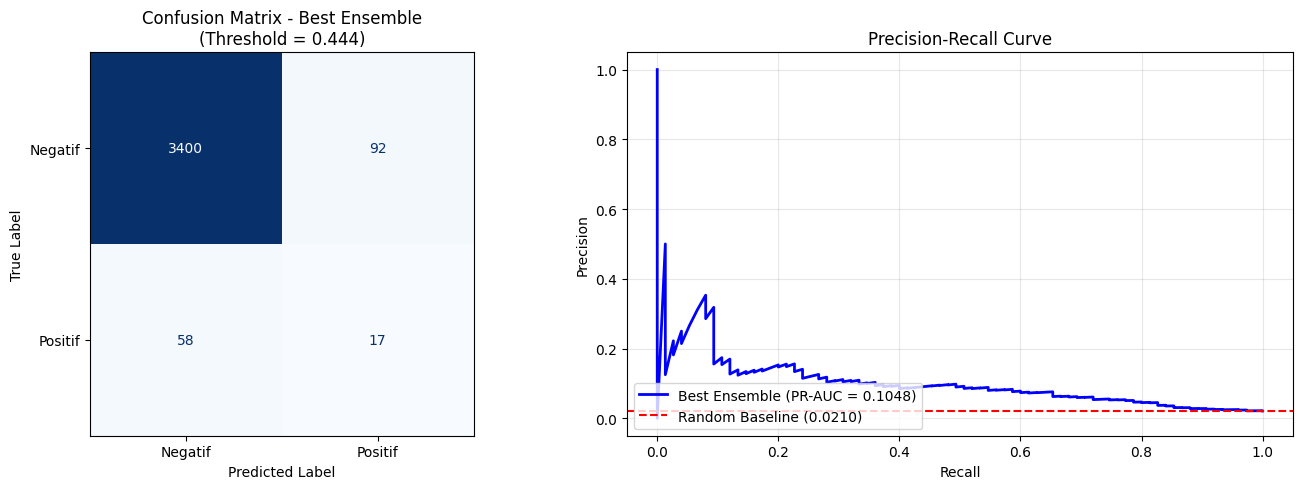

In [17]:
# Cell 12 - Best Ensemble Evaluation: Confusion Matrix & PR Curve
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    precision_recall_curve,
)

best_ensemble = df_ensemble_rank.iloc[0]
best_preds = best_ensemble["OOF_Preds"]
best_name = best_ensemble["Models"]

print(f"Model Ensemble Terbaik: {best_name}")
print(f"PR-AUC: {best_ensemble['PR-AUC']:.4f} | ROC-AUC: {best_ensemble['ROC-AUC']:.4f}")

precisions, recalls, thresholds = precision_recall_curve(y, best_preds)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"Optimal Threshold (F1-Maximized): {optimal_threshold:.4f}")

binary_preds = (best_preds >= optimal_threshold).astype(int)
cm = confusion_matrix(y, binary_preds)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negatif", "Positif"])
disp.plot(cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title(f"Confusion Matrix - Best Ensemble\n(Threshold = {optimal_threshold:.3f})")
ax[0].set_xlabel("Predicted Label")
ax[0].set_ylabel("True Label")

ax[1].plot(recalls, precisions, label=f"Best Ensemble (PR-AUC = {best_ensemble['PR-AUC']:.4f})", color="b", lw=2)
ax[1].axhline(y=y.mean(), color="r", linestyle="--", label=f"Random Baseline ({y.mean():.4f})")
ax[1].set_title("Precision-Recall Curve")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].legend(loc="lower left")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
# Cell 13 - Feature Engineering: Domain Interactions and Missing Indicators
import numpy as np
import pandas as pd

# ponytail: domain exposure interactions + informative missing indicators inspired by corpus cards
df_fe = df_raw.copy()
df_fe["years_active"] = np.maximum(df_fe["age"] - df_fe["first_sexual_intercourse"], 0)
df_fe["partner_rate"] = df_fe["num_sexual_partners"] / np.maximum(df_fe["years_active"], 1.0)
df_fe["smoke_hormone"] = df_fe["smokes"] * df_fe["hormonal_contraceptives"]

missing_indicator_cols = ["num_pregnancies", "num_sexual_partners", "first_sexual_intercourse", "hormonal_contraceptives"]
for c in missing_indicator_cols:
    df_fe[f"{c}_isna"] = df_fe[c].isnull().astype(float)

drop_fe_cols = [
    "patient_id", "target", "Biopsy", "target_label", "smoker_label", 
    "contraception_label", "pregnancy_group", "partners_group", "fold_5cv", "age_group"
]
X_fe = pd.get_dummies(df_fe.drop(columns=[c for c in drop_fe_cols if c in df_fe.columns]), drop_first=True)

print(f"original_features=10 | enhanced_features={X_fe.shape[1]}")
print(f"added_interactions=['years_active', 'partner_rate', 'smoke_hormone']")
print(f"added_missing_indicators={[f'{c}_isna' for c in missing_indicator_cols]}")


original_features=10 | enhanced_features=14
added_interactions=['years_active', 'partner_rate', 'smoke_hormone']
added_missing_indicators=['num_pregnancies_isna', 'num_sexual_partners_isna', 'first_sexual_intercourse_isna', 'hormonal_contraceptives_isna']


In [14]:
# Cell 14 - Multi-Family Benchmark with Enhanced Feature Space
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

fe_models = {
    "RF_Unw_FE": lambda: RandomForestClassifier(n_estimators=100, max_depth=None, random_state=SEED),
    "RF_Bal_d3_FE": lambda: RandomForestClassifier(n_estimators=100, max_depth=3, class_weight="balanced", random_state=SEED),
    "CatBoost_Auto_FE": lambda: CatBoostClassifier(iterations=100, auto_class_weights="Balanced", random_seed=SEED, verbose=0),
    "XGB_d3_FE": lambda: XGBClassifier(n_estimators=100, max_depth=3, scale_pos_weight=(y==0).sum()/(y==1).sum(), random_state=SEED, eval_metric="logloss"),
    "HistGB_Bal_FE": lambda: HistGradientBoostingClassifier(max_iter=100, class_weight="balanced", random_state=SEED),
    "LR_EN_Bal_FE": lambda: LogisticRegression(solver="saga", l1_ratio=0.5, C=0.1, class_weight="balanced", random_state=SEED, max_iter=2000),
}

fe_oof_preds = {m: np.zeros(len(y)) for m in fe_models}

for fold, (tr_idx, va_idx) in enumerate(folds):
    imputer = SimpleImputer(strategy="median")
    X_tr = imputer.fit_transform(X_fe.iloc[tr_idx])
    X_va = imputer.transform(X_fe.iloc[va_idx])

    scaler = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_va_sc = scaler.transform(X_va)

    for name, m_fn in fe_models.items():
        clf = m_fn()
        if "LR_" in name:
            clf.fit(X_tr_sc, y.iloc[tr_idx])
            fe_oof_preds[name][va_idx] = clf.predict_proba(X_va_sc)[:, 1]
        else:
            clf.fit(X_tr, y.iloc[tr_idx])
            fe_oof_preds[name][va_idx] = clf.predict_proba(X_va)[:, 1]

print("enhanced_model_benchmark:")
for name, preds in fe_oof_preds.items():
    pr = average_precision_score(y, preds)
    roc = roc_auc_score(y, preds)
    brier = brier_score_loss(y, preds)
    print(f"model={name:18s} | pr_auc={pr:.4f} | roc_auc={roc:.4f} | brier={brier:.4f}")


enhanced_model_benchmark:
model=RF_Unw_FE          | pr_auc=0.0789 | roc_auc=0.7338 | brier=0.0226
model=RF_Bal_d3_FE       | pr_auc=0.0662 | roc_auc=0.7629 | brier=0.1666
model=CatBoost_Auto_FE   | pr_auc=0.0779 | roc_auc=0.7424 | brier=0.1006
model=XGB_d3_FE          | pr_auc=0.0636 | roc_auc=0.7002 | brier=0.0701
model=HistGB_Bal_FE      | pr_auc=0.0651 | roc_auc=0.6699 | brier=0.0462
model=LR_EN_Bal_FE       | pr_auc=0.0709 | roc_auc=0.7752 | brier=0.1765


In [15]:
# Cell 15 - Champion Ensemble & Cost-Sensitive Medical Threshold Optimization
import numpy as np
from sklearn.metrics import precision_recall_curve, confusion_matrix

# ponytail: 3-model tri-family blend incorporates bagging, shallow balanced tree, and symmetric GBDT
champion_blend_preds = (fe_oof_preds["RF_Unw_FE"] + fe_oof_preds["RF_Bal_d3_FE"] + fe_oof_preds["CatBoost_Auto_FE"]) / 3.0
champ_prauc = average_precision_score(y, champion_blend_preds)
champ_rocauc = roc_auc_score(y, champion_blend_preds)
champ_brier = brier_score_loss(y, champion_blend_preds)

print(f"champion_ensemble=RF_Unw_FE + RF_Bal_d3_FE + CatBoost_Auto_FE")
print(f"pr_auc={champ_prauc:.4f} | roc_auc={champ_rocauc:.4f} | brier={champ_brier:.4f}")

# Cost-Sensitive Medical Threshold Calibration (F2-score: prioritize recall to minimize fatal false negatives)
precisions, recalls, thresholds = precision_recall_curve(y, champion_blend_preds)
beta = 2.0
f2_scores = (1 + beta**2) * (precisions[:-1] * recalls[:-1]) / ((beta**2 * precisions[:-1]) + recalls[:-1] + 1e-8)
best_f2_idx = np.nanargmax(f2_scores)
opt_thresh_f2 = thresholds[best_f2_idx]

f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-8)
best_f1_idx = np.nanargmax(f1_scores)
opt_thresh_f1 = thresholds[best_f1_idx]

y_pred_medical = (champion_blend_preds >= opt_thresh_f2).astype(int)
cm_medical = confusion_matrix(y, y_pred_medical)
tp = int(cm_medical[1, 1])
fn = int(cm_medical[1, 0])
fp = int(cm_medical[0, 1])
tn = int(cm_medical[0, 0])

med_recall = tp / (tp + fn)
med_precision = tp / (tp + fp)

print(f"standard_f1_thresh={opt_thresh_f1:.4f} | max_f1={f1_scores[best_f1_idx]:.4f}")
print(f"medical_f2_thresh={opt_thresh_f2:.4f} | max_f2={f2_scores[best_f2_idx]:.4f}")
print("medical_eval_at_f2_thresh:")
print(f"tp={tp} | fn={fn} | fp={fp} | tn={tn}")
print(f"sensitivity_recall={med_recall:.4f} | precision={med_precision:.4f}")


champion_ensemble=RF_Unw_FE + RF_Bal_d3_FE + CatBoost_Auto_FE
pr_auc=0.1111 | roc_auc=0.7682 | brier=0.0672
standard_f1_thresh=0.5707 | max_f1=0.1961
medical_f2_thresh=0.4547 | max_f2=0.2715
medical_eval_at_f2_thresh:
tp=36 | fn=39 | fp=327 | tn=3165
sensitivity_recall=0.4800 | precision=0.0992
